# App Insights Unlocked: Google Play Store Analysis
Python solution to the 25 case-study questions (10 Basic, 10 Medium, 5 Advanced) on the Kaggle `googleplaystore.csv` (10,841 rows, 13 columns) and `googleplaystore_user_reviews.csv` (64,295 rows). Pandas, NumPy, Matplotlib, Seaborn.

Installs are bands (for example `1,000,000+`), so install totals use the lower bound and are approximate. The data is a snapshot to 8 August 2018.

In [1]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt, re, collections, warnings
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')
raw = pd.read_csv('../data/googleplaystore.csv'); rev = pd.read_csv('../data/googleplaystore_user_reviews.csv')
print(raw.shape, rev.shape); raw.head(3)

(10841, 13) (64295, 5)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up


## 1. Data cleaning

In [2]:
print(raw.isna().sum()[lambda s:s>0])
print('Corrupted row (shifted columns):'); display(raw[raw.Category=='1.9'][['App','Category','Rating','Reviews']])
print('Duplicate App names:', raw.App.duplicated().sum())

Rating            1474
Type                 1
Content Rating       1
Current Ver          8
Android Ver          3
dtype: int64
Corrupted row (shifted columns):


,App,Category,Rating,Reviews
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M


Duplicate App names: 1181


**Decisions**
- 1 corrupted row (Category = `1.9`, columns shifted) is removed.
- `Type` has 1 missing value with price 0, so it is Free. `Rating` is blank for 1,463 apps: these are left blank and excluded from rating analyses (not filled in). Size `Varies with device` is excluded from size analyses.
- `Installs`, `Price` and `Size` are converted to numbers (`k` sizes divided by 1,024); `Last Updated` becomes a date.
- 1,181 repeated App names are removed, keeping the row with the most reviews.
- Category names are made readable (`PHOTOGRAPHY` to `Photography`).

In [3]:
d = raw[raw.Category!='1.9'].copy(); d['Type']=d.Type.fillna('Free')
d['Reviews']=d.Reviews.astype(float).astype(int)
d['Installs_n']=d.Installs.str.replace('[+,]','',regex=True).astype(float)
d['Price_n']=d.Price.str.replace('$','',regex=False).astype(float)
def sz(s):
    if s.endswith('M'): return float(s[:-1])
    if s.endswith('k'): return float(s[:-1])/1024
    return np.nan
d['Size_MB']=d.Size.map(sz); d['Updated']=pd.to_datetime(d['Last Updated'],format='%B %d, %Y')
n0=len(d); d=d.sort_values(['App','Reviews'],ascending=[True,False]).drop_duplicates('App',keep='first')
d['Category_c']=d.Category.str.replace('_',' ').str.title().str.replace('And','and'); d['Genre1']=d.Genres.str.split(';').str[0]
d=d.reset_index(drop=True); x=d.dropna(subset=['Rating'])
print('Rows:',len(raw),'| after removing corrupted row:',n0,'| unique apps:',len(d),'| rated apps:',len(x))
d.drop(columns=['Genre1']).to_csv('../data/googleplaystore_cleaned.csv',index=False)

Rows: 10841 | after removing corrupted row: 10840 | unique apps: 9659 | rated apps: 8196


## 2. Basic questions

Q1 average rating: 4.17 over 8196 rated apps (median 4.3 )
Q2 unique categories: 33
Q3 size: mean 20.4 median 12.0 apps with size 8431 max 100.0


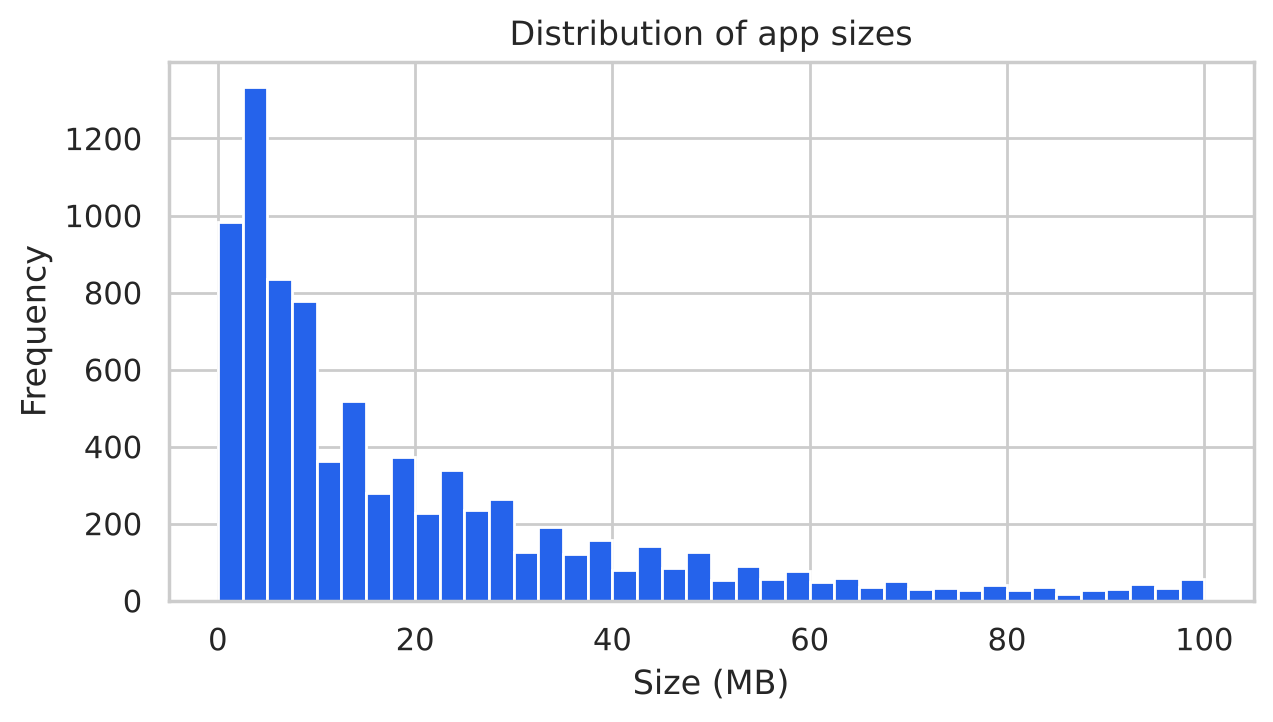

Size_MB
(0, 1]        3.8
(1, 5]       23.7
(5, 10]      19.1
(10, 20]     18.2
(20, 50]     24.8
(50, 100]    10.4
Name: proportion, dtype: float64
Q4 free vs paid: {'Free': 8905, 'Paid': 754} 92.2 % free
Q5 content rating: {'Everyone': 7903, 'Teen': 1036, 'Mature 17+': 393} 81.8 % Everyone


In [4]:
print('Q1 average rating:', round(x.Rating.mean(),2), 'over', len(x), 'rated apps (median', x.Rating.median(),')')
print('Q2 unique categories:', d.Category.nunique())
s=d.Size_MB.dropna(); print('Q3 size: mean',round(s.mean(),1),'median',s.median(),'apps with size',len(s),'max',s.max())
s.plot.hist(bins=40,figsize=(7,3.5),color='#2563eb'); plt.xlabel('Size (MB)'); plt.title('Distribution of app sizes'); plt.show()
print(pd.cut(s,[0,1,5,10,20,50,100]).value_counts(normalize=True).sort_index().mul(100).round(1))
print('Q4 free vs paid:', d.Type.value_counts().to_dict(), round((d.Type=='Free').mean()*100,1),'% free')
print('Q5 content rating:', d['Content Rating'].value_counts().head(3).to_dict(), round((d['Content Rating']=='Everyone').mean()*100,1),'% Everyone')

In [5]:
print('Q6 apps in the top install band (1B+):', (d.Installs_n>=1e9).sum(), '- ties are broken by reviews')
display(d.sort_values(['Installs_n','Reviews'],ascending=False)[['App','Category_c','Installs','Reviews','Rating']].head(5))
print('Q7 rated 4.0 or above:', int((x.Rating>=4).sum()), f'({(x.Rating>=4).mean()*100:.1f}% of rated apps)')
print('Q8 reviews, free vs paid'); display(d.groupby('Type').Reviews.agg(['mean','median']).round(0))
g=d.groupby('Category_c').Size_MB.mean().round(1).sort_values(ascending=False); print('Q9 average size by category (MB): largest'); display(g.head(3)); print('smallest'); display(g.tail(3))
print('Q10 apps last updated in 2018:', int((d.Updated.dt.year==2018).sum()), f'({(d.Updated.dt.year==2018).mean()*100:.1f}%); newest date', d.Updated.max().date())

Q6 apps in the top install band (1B+): 20 - ties are broken by reviews


,App,Category_c,Installs,Reviews,Rating
4328,Facebook,Social,"1,000,000,000+",78158306,4.1
9041,WhatsApp Messenger,Communication,"1,000,000,000+",69119316,4.4
5399,Instagram,Social,"1,000,000,000+",66577446,4.5
6165,Messenger – Text and Video Chat for Free,Communication,"1,000,000,000+",56646578,4.0
8079,Subway Surfers,Game,"1,000,000,000+",27725352,4.5


Q7 rated 4.0 or above: 6287 (76.7% of rated apps)
Q8 reviews, free vs paid


,mean,median
Type,,
Free,234421.0,1379.0
Paid,8748.0,88.0


Q9 average size by category (MB): largest


Category_c
Game                41.7
Family              27.3
Travel and Local    24.2
Name: Size_MB, dtype: float64

smallest


Category_c
Personalization       11.2
Libraries and Demo    10.6
Tools                  8.8
Name: Size_MB, dtype: float64

Q10 apps last updated in 2018: 6287 (65.1%); newest date 2018-08-08


## 3. Medium questions

In [6]:
print('M1 installs vs rating: Pearson', round(x.Installs_n.corr(x.Rating),3), '| Spearman', round(x.Installs_n.corr(x.Rating,method='spearman'),3))
g=x.groupby('Category_c').Rating.agg(['mean','count']).round(3).sort_values('mean',ascending=False); print('M2 highest-rated categories'); display(g.head(5)); display(g.tail(3))
p=x[x.Price_n>0]; pb=pd.cut(p.Price_n,[0,1,2,5,10,1000],labels=['<=1','1-2','2-5','5-10','>10'])
print('M3 paid apps (rated):',len(p),'| price vs rating correlation',round(p.Price_n.corr(p.Rating),3),'| paid mean',round(p.Rating.mean(),2),'vs free',round(x[x.Type=='Free'].Rating.mean(),2)); display(p.groupby(pb,observed=True).Rating.agg(['mean','count']).round(2))

M1 installs vs rating: Pearson 0.04 | Spearman 0.027
M2 highest-rated categories


,mean,count
Category_c,,
Events,4.436,45
Art and Design,4.359,59
Education,4.355,106
Books and Reference,4.345,169
Personalization,4.332,298


,mean,count
Category_c,,
Tools,4.040,720
Maps and Navigation,4.036,118
Dating,3.980,133


M3 paid apps (rated): 602 | price vs rating correlation -0.114 | paid mean 4.26 vs free 4.17


,mean,count
Price_n,,
<=1,4.30,106
1-2,4.29,101
2-5,4.26,282
5-10,4.26,58
>10,4.13,55


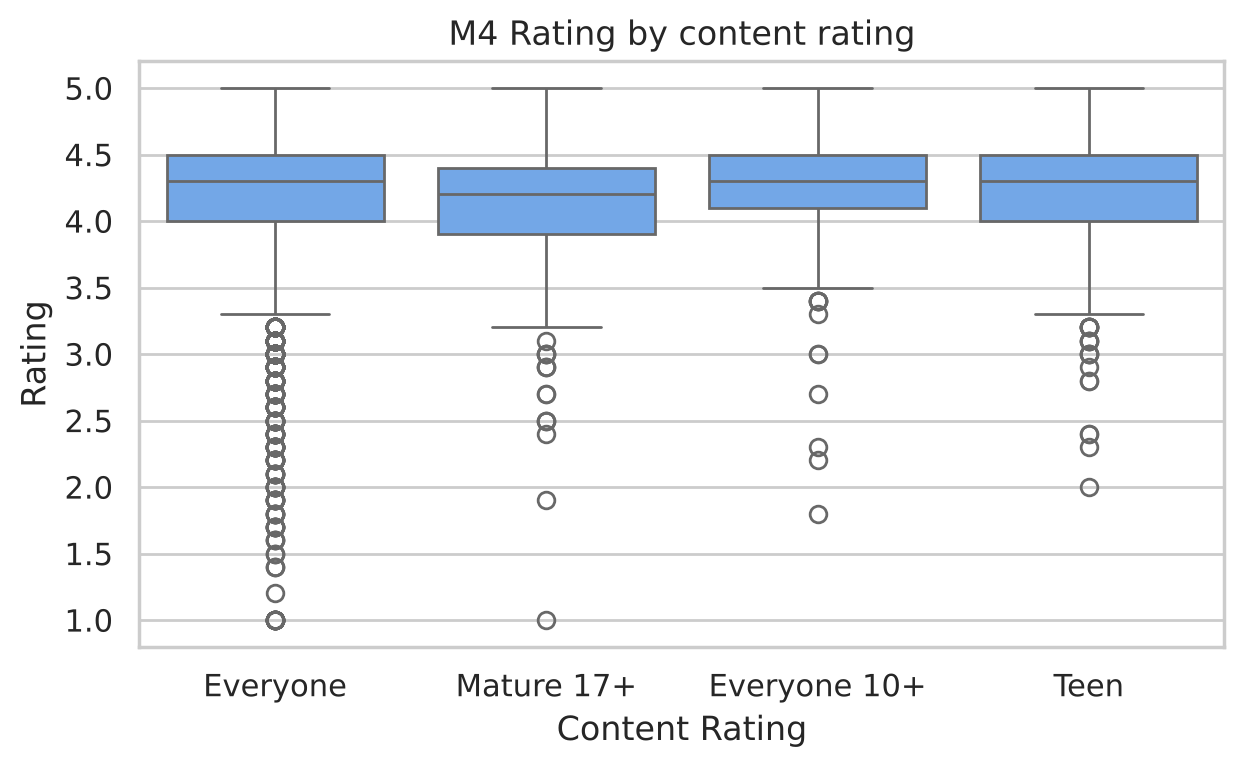

,count,mean,median
Content Rating,,,
Adults only 18+,3,4.30,4.5
Everyone,6618,4.17,4.3
Everyone 10+,305,4.23,4.3
Mature 17+,357,4.12,4.2
Teen,912,4.23,4.3
Unrated,1,4.10,4.1


M5 apps with 1M+ installs: 3398


Genres
Tools            274
Action           180
Photography      173
Entertainment    154
Productivity     147
Name: count, dtype: int64

In [7]:
plt.figure(figsize=(7,3.8)); sns.boxplot(x='Content Rating',y='Rating',data=x[x['Content Rating'].isin(['Everyone','Everyone 10+','Teen','Mature 17+'])],color='#60a5fa'); plt.title('M4 Rating by content rating'); plt.show()
display(x.groupby('Content Rating').Rating.agg(['count','mean','median']).round(2))
big=d[d.Installs_n>=1e6]; print('M5 apps with 1M+ installs:',len(big)); display(big.Genres.value_counts().head(5))

M6 Each app has ONE Last Updated date, so time between updates cannot be calculated. Alternative - days since last update: mean 281 median 96.0 | updated within 90 days: 49 % | over a year ago: 25 %


M7 size vs installs: Pearson 0.134 Spearman 0.31


,median,count
Size_MB,,
"(0, 10]",10000.0,3930
"(10, 20]",50000.0,1533
"(20, 30]",100000.0,1067
"(30, 50]",500000.0,1025
"(50, 100]",1000000.0,876


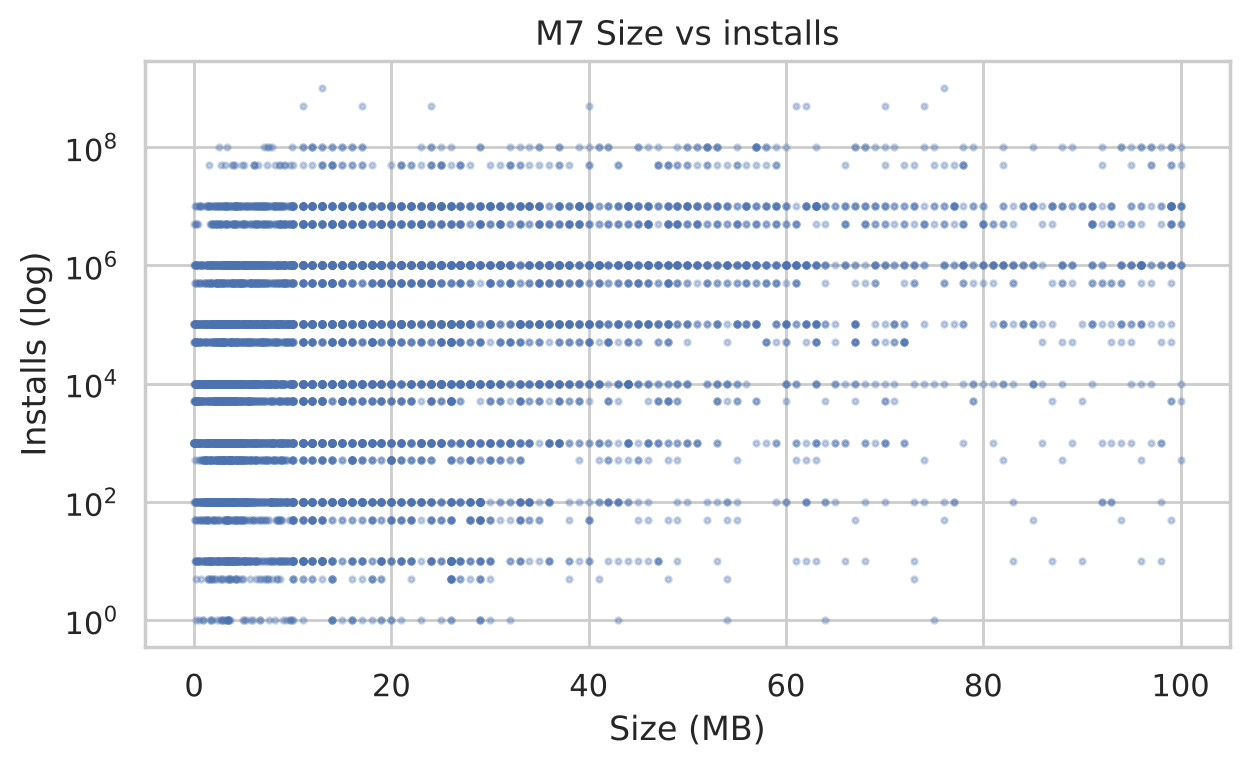

In [8]:
age=(d.Updated.max()-d.Updated).dt.days
print('M6 Each app has ONE Last Updated date, so time between updates cannot be calculated. Alternative - days since last update: mean',round(age.mean()),'median',age.median(),'| updated within 90 days:',round((age<=90).mean()*100),'% | over a year ago:',round((age>365).mean()*100),'%')
ss=d.dropna(subset=['Size_MB']); print('M7 size vs installs: Pearson',round(ss.Size_MB.corr(ss.Installs_n),3),'Spearman',round(ss.Size_MB.corr(ss.Installs_n,method='spearman'),3))
sb=pd.cut(ss.Size_MB,[0,10,20,30,50,100]); display(ss.groupby(sb,observed=True).Installs_n.agg(['median','count']))
plt.figure(figsize=(7,3.8)); plt.scatter(ss.Size_MB,ss.Installs_n,s=4,alpha=.3); plt.yscale('log'); plt.xlabel('Size (MB)'); plt.ylabel('Installs (log)'); plt.title('M7 Size vs installs'); plt.show()

In [9]:
print('M8 most reviewed apps'); display(d.sort_values('Reviews',ascending=False)[['App','Reviews','Rating','Installs']].head(5))
print('M9 content rating share within free and paid (%)'); display(pd.crosstab(d['Content Rating'],d.Type,normalize='columns').mul(100).round(1)); display(pd.crosstab(d['Content Rating'],d.Type))
print('M10 top 5 categories by installs (lower bound)'); display((d.groupby('Category_c').Installs_n.sum().sort_values(ascending=False).head(5)/1e9).round(1).rename('billions'))

M8 most reviewed apps


,App,Reviews,Rating,Installs
4328,Facebook,78158306,4.1,"1,000,000,000+"
9041,WhatsApp Messenger,69119316,4.4,"1,000,000,000+"
5399,Instagram,66577446,4.5,"1,000,000,000+"
6165,Messenger – Text and Video Chat for Free,56646578,4.0,"1,000,000,000+"
2564,Clash of Clans,44893888,4.6,"100,000,000+"


M9 content rating share within free and paid (%)


Type,Free,Paid
Content Rating,,
Adults only 18+,0.0,0.0
Everyone,81.4,86.6
Everyone 10+,3.3,4.1
Mature 17+,4.2,2.4
Teen,11.0,6.9
Unrated,0.0,0.0


Type,Free,Paid
Content Rating,,
Adults only 18+,3,0
Everyone,7250,653
Everyone 10+,291,31
Mature 17+,375,18
Teen,984,52
Unrated,2,0


M10 top 5 categories by installs (lower bound)


Category_c
Game             13.5
Communication    11.0
Tools             8.1
Family            6.2
Productivity      5.8
Name: billions, dtype: float64

## 4. Advanced questions

In [10]:
a=x[x.Rating==5]; print('A1 apps rated exactly 5.0:',len(a),'| median reviews',a.Reviews.median(),'| median installs',a.Installs_n.median(),'-> a 5.0 rating is not a reliable signal')
print('Top rated with at least 1,000 reviews:'); display(x[x.Reviews>=1000].sort_values(['Rating','Reviews'],ascending=False)[['App','Rating','Reviews','Installs']].head(10))

A1 apps rated exactly 5.0: 271 | median reviews 4.0 | median installs 100.0 -> a 5.0 rating is not a reliable signal
Top rated with at least 1,000 reviews:


,App,Rating,Reviews,Installs
5450,JW Library,4.9,922752,"10,000,000+"
7822,Six Pack in 30 Days - Abs Workout,4.9,272337,"10,000,000+"
8469,Tickets + PDA 2018 Exam,4.9,197136,"1,000,000+"
5750,"Learn Japanese, Korean, Chinese Offline & Free",4.9,133136,"1,000,000+"
8067,StrongLifts 5x5 Workout Gym Log & Personal Tra...,4.9,66791,"1,000,000+"
7020,PixPanda - Color by Number Pixel Art Coloring ...,4.9,55723,"1,000,000+"
9509,"ipsy: Makeup, Beauty, and Tips",4.9,49790,"1,000,000+"
5282,Hungry Hearts Diner: A Tale of Star-Crossed Souls,4.9,46253,"500,000+"
5884,Lose Belly Fat in 30 Days - Flat Stomach,4.9,38098,"5,000,000+"
7926,Solitaire: Decked Out Ad Free,4.9,37302,"500,000+"


A2 apps by last-updated year: {2010: 1, 2011: 15, 2012: 26, 2013: 108, 2014: 203, 2015: 448, 2016: 779, 2017: 1792, 2018: 6287}


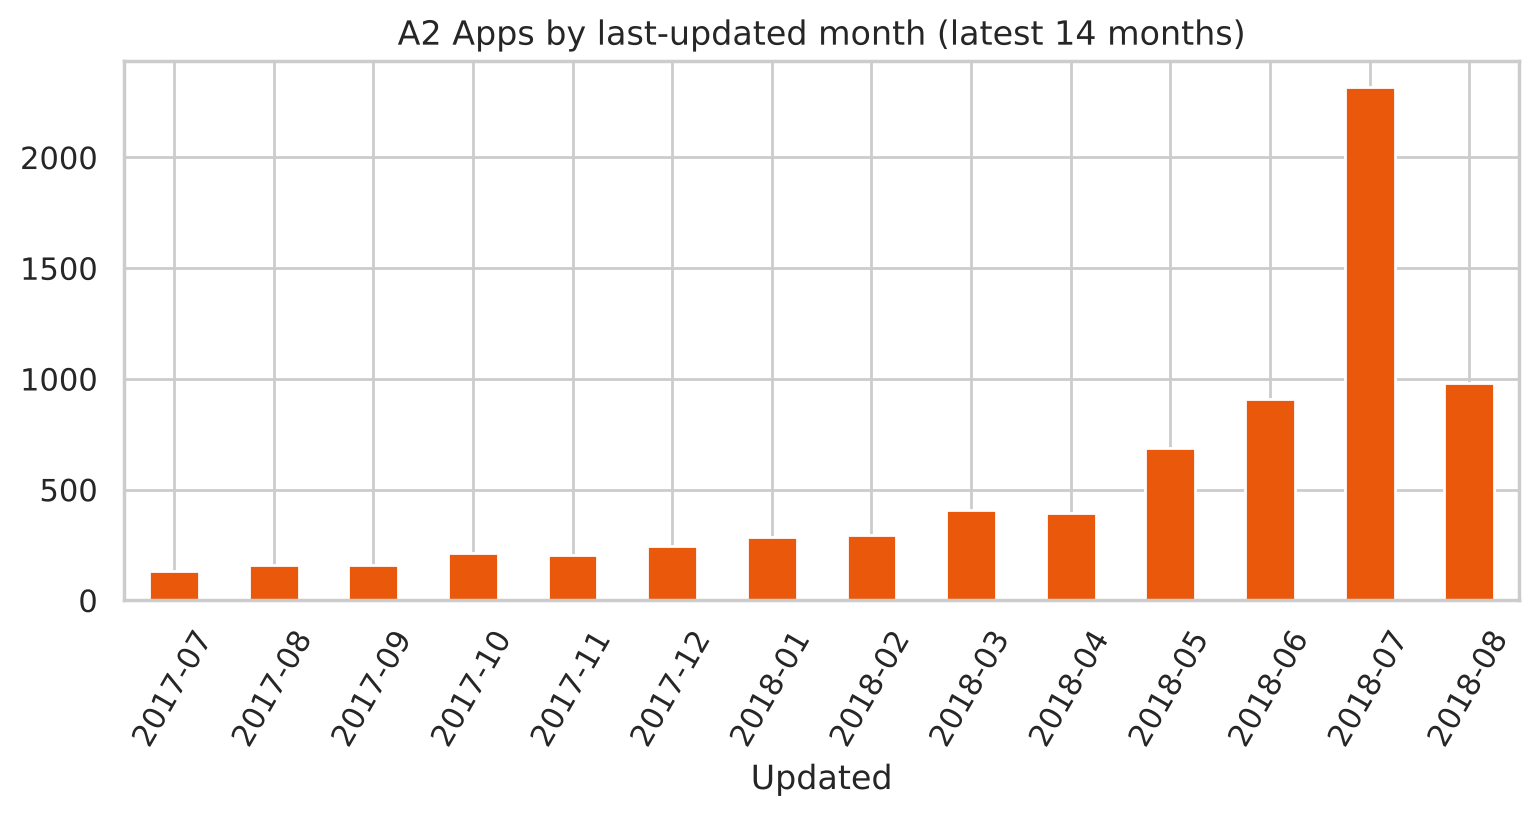

Counts climb towards the snapshot date (Aug 2018), so this reflects when the data was collected; no clean seasonal pattern can be separated.


In [11]:
print('A2 apps by last-updated year:',d.Updated.dt.year.value_counts().sort_index().to_dict())
m=d.groupby(d.Updated.dt.to_period('M')).size().tail(14); m.index=m.index.astype(str)
m.plot(kind='bar',figsize=(9,3.5),color='#ea580c'); plt.title('A2 Apps by last-updated month (latest 14 months)'); plt.xticks(rotation=60); plt.show()
print('Counts climb towards the snapshot date (Aug 2018), so this reflects when the data was collected; no clean seasonal pattern can be separated.')

,mean,count
Installs_n,,
<=1K,4.199,1334
1K-10K,4.031,1411
10K-100K,4.095,1552
100K-1M,4.204,1918
1M-10M,4.271,1544
10M-100M,4.359,393
100M+,4.302,44


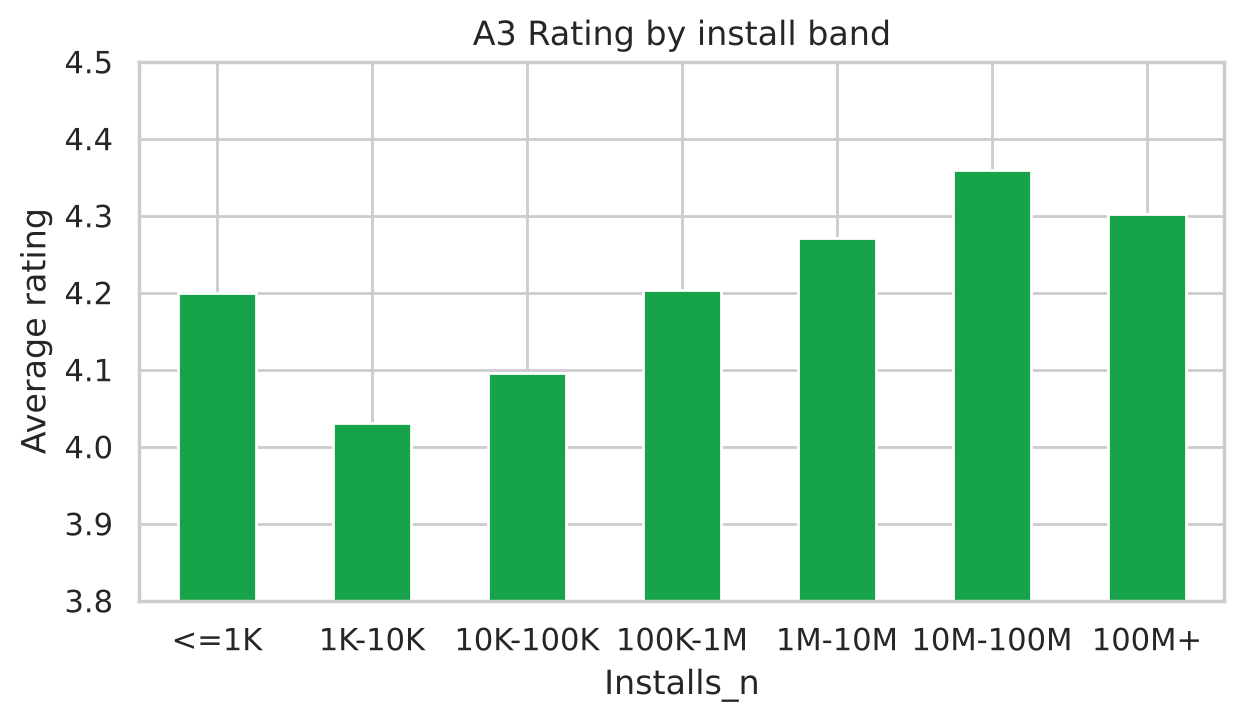

In [12]:
ib=pd.cut(x.Installs_n,[-1,1e3,1e4,1e5,1e6,1e7,1e8,1e12],labels=['<=1K','1K-10K','10K-100K','100K-1M','1M-10M','10M-100M','100M+'])
t=x.groupby(ib,observed=True).Rating.agg(['mean','count']).round(3); display(t)
t['mean'].plot(kind='bar',figsize=(7,3.5),color='#16a34a'); plt.ylim(3.8,4.5); plt.ylabel('Average rating'); plt.title('A3 Rating by install band'); plt.xticks(rotation=0); plt.show()

In [13]:
# A4 sentiment: uses the labelled sentiment in the reviews file (positive/neutral/negative), joined to rated apps
r=rev.dropna(subset=['Sentiment']).merge(x[['App','Rating']],on='App')
print('Labelled reviews:',len(r),'for',r.App.nunique(),'rated apps'); print((r.Sentiment.value_counts(normalize=True)*100).round(1).to_dict())
r['band']=pd.cut(r.Rating,[0,3.99,4.35,5],labels=['under 4.0','4.0-4.3','4.4+'])
display((pd.crosstab(r.band,r.Sentiment,normalize='index')*100).round(1))
stop=set('the a an and or to of is it in for this that i my me app was are but with have has be you on not so very its just can get all your they as at from will if one use there do when what too more also out up would how really'.split())
def words(df):
    c=collections.Counter(w for t in df.Translated_Review.dropna() for w in re.findall(r"[a-z']{3,}",t.lower()) if w not in stop); return c
pos=words(r[r.Sentiment=='Positive']); neg=words(r[r.Sentiment=='Negative'])
print('Most common words in positive reviews:',[w for w,_ in pos.most_common(10)]); print('Most common words in negative reviews:',[w for w,_ in neg.most_common(10)])
# words used much more in negative than positive reviews (relative frequency, at least 100 uses)
rel={w:(neg[w]/sum(neg.values()))/((pos[w]+1)/sum(pos.values())) for w in neg if neg[w]>=100}
print('Words most specific to negative reviews:',sorted(rel,key=rel.get,reverse=True)[:12])

Labelled reviews: 35934 for 816 rated apps
{'Positive': 64.2, 'Negative': 22.3, 'Neutral': 13.5}


Sentiment,Negative,Neutral,Positive
band,,,
under 4.0,27.6,18.4,54.0
4.0-4.3,21.8,16.4,61.8
4.4+,21.4,10.0,68.5


Most common words in positive reviews: ['game', 'good', 'great', 'love', 'like', 'time', 'easy', "it's", 'best', 'much']
Most common words in negative reviews: ['game', 'time', 'like', 'even', 'play', "can't", 'ads', 'update', "i'm", 'phone']
Words most specific to negative reviews: ['horrible', 'worst', 'terrible', 'stupid', 'awful', 'hate', 'boring', 'useless', 'annoying', 'unable', 'fake', 'worse']


In [14]:
g=x.groupby('Genres').Rating.agg(['mean','median','count']); g=g[g['count']>=20].round(3).sort_values('mean',ascending=False)
print('A5 genres with at least 20 rated apps:',len(g)); display(g.head(5)); display(g.tail(5))

A5 genres with at least 20 rated apps: 49


,mean,median,count
Genres,,,
Events,4.436,4.5,45
Puzzle,4.370,4.4,100
Art & Design,4.358,4.4,55
Books & Reference,4.345,4.5,169
Parenting,4.340,4.5,40


,mean,median,count
Genres,,,
Tools,4.040,4.20,719
Trivia,4.039,4.25,28
Maps & Navigation,4.036,4.20,118
Dating,3.980,4.10,133
Educational,3.872,3.95,32


## 5. Insights and recommendations
- **Go free first:** 92% of apps are free and free apps get about 27 times the reviews.
- **Quality, not popularity, lifts ratings:** installs and rating are almost uncorrelated (0.04), but apps with 10M to 100M installs average 4.36 vs 4.03 for 1K to 10K installs; protect the rating early.
- **Demand:** Game, Communication and Tools lead installs; Education, Books and Reference and Art and Design pair high ratings with fewer apps.
- **Size is not the barrier:** bigger apps (mostly games) have more installs.
- **Keep updating, read reviews:** complaints centre on ads, updates and in-app money.
- **Limits:** installs are bands; one update date per app; sentiment covers 816 apps only; association, not causation.